<a href="https://colab.research.google.com/github/Atika-Adelia/Repo-Kelompok07-ProyekStudio02/blob/main/studio2_kelompok07_rb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Studio 2 — Kompetisi Klasifikasi Sampah (5 kelas)**

## **Deep Learning (IF25-40401) | Teknik Informatika | Institut Teknologi Sumatera**

---

### **Nama Anggota Kelompok :**
### **1. Hildyah Maretasya Araffad (123140151)**
### **2. Firman H Gultom (123140171)**
### **3. Atika Adelia (123140172)**



## 1. Setup, Konfigurasi, dan Reproduktibilitas


In [ ]:
import os, sys, json, math, copy, time, random, shutil, hashlib, platform, subprocess, importlib.util, urllib.request, gc
from dataclasses import dataclass, asdict, replace
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

IN_COLAB = 'google.colab' in sys.modules

try:
    import timm
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm'])
    import timm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode
from timm.data import Mixup
from timm.loss import SoftTargetCrossEntropy
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw):
        return x

# Kelas
CLASSES = ['botol_plastik', 'gelas_plastik', 'kertas_kardus', 'saset_kemasan', 'styrofoam']
NUM_CLASSES = len(CLASSES)
# Jenis format file
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp'}

In [ ]:
@dataclass
class CFG:
    # Path
    data_root: str = '/content/drive/MyDrive/dataset_studio2'
    repo_dir: str = '/content/studio2' if IN_COLAB else '.'
    sources_csv: str = ''
    copy_to_local: bool = True
    local_data_dir: str = 'data_local'
    backup_dir: str = '/content/drive/MyDrive/studio2_backup'
    extra_dirs: tuple = ()
    cache_dir: str = 'cache'
    runs_dir: str = 'runs'
    cache_max_side: int = 512

    # Model
    backbone: str = 'convnext_tiny.fb_in22k_ft_in1k'
    img_size: int = 224
    drop_path: float = 0.1
    drop_rate: float = 0.2

    # Optimasi
    epochs: int = 15
    warmup_epochs: int = 1
    batch_size: int = 32
    lr_backbone: float = 1e-4
    lr_head: float = 1e-3
    weight_decay: float = 0.05
    label_smoothing: float = 0.1
    mixup: float = 0.2
    cutmix: float = 1.0
    mix_prob: float = 0.5
    mix_off_last: int = 3
    ema_decay: float = 0.995
    grad_clip: float = 1.0
    sampler: str = 'none'

    # Evaluasi
    val_frac: float = 0.15
    select: str = 'last'

    # Sistem
    seed: int = 42
    num_workers: int = (
        0 if platform.system() == 'Windows'
        else min(4, os.cpu_count() or 2)
    )
    amp: bool = True


cfg = CFG()
assert cfg.batch_size % 2 == 0, 'batch_size harus genap'

REPO = Path(cfg.repo_dir)
REPO.mkdir(parents=True, exist_ok=True)
REPO = REPO.resolve()
os.chdir(REPO)


def drive_backup_dir():
    if IN_COLAB and Path('/content/drive/MyDrive').is_dir():
        return Path(cfg.backup_dir)
    return None


def backup_to_drive(paths=('runs', 'submission', 'README.md', '.gitignore')):
    bd = drive_backup_dir()
    if bd is None:
        return
    n = 0
    for p in paths:
        src = Path(p)
        if not src.exists():
            continue
        files = [src] if src.is_file() else [f for f in src.rglob('*') if f.is_file()]
        for f in files:
            dst = bd / f
            if dst.exists() and dst.stat().st_size == f.stat().st_size:
                continue
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(f, dst)
            n += 1
    if n:
        print(f'[backup] {n} file disalin ke {bd}')


def restore_from_drive():
    bd = drive_backup_dir()
    if bd is None or not (bd / 'runs').exists():
        return
    n = 0
    for sub in ('runs', 'submission'):
        for f in (bd / sub).rglob('*') if (bd / sub).exists() else []:
            if f.is_file() and not (REPO / sub / f.relative_to(bd / sub)).exists():
                dst = REPO / sub / f.relative_to(bd / sub)
                dst.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(f, dst)
                n += 1
    if n:
        print(f'[restore] {n} file dipulihkan dari {bd}')


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Runtime type
seed_everything(cfg.seed)
if torch.cuda.is_available():
    DEVICE = 'cuda'
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = 'mps'
else:
    DEVICE = 'cpu'
USE_AMP = cfg.amp and DEVICE == 'cuda'
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.get_device_capability()[0] >= 8) else torch.float16
torch.backends.cudnn.benchmark = True

print(f'Repo         : {REPO}')
print(f'torch/timm   : {torch.__version__} / {timm.__version__}')
print(f'Device       : {DEVICE}' + (f' ({torch.cuda.get_device_name(0)})' if DEVICE == 'cuda' else ''))
print(f'AMP          : {USE_AMP} ({AMP_DTYPE if USE_AMP else "-"})')
print(f'Backbone     : {cfg.backbone} @ {cfg.img_size}px | {cfg.epochs} epoch | batch {cfg.batch_size}')

Repo         : /content/studio2
torch/timm   : 2.11.0+cu130 / 1.0.30
Device       : cuda (Tesla T4)
AMP          : True (torch.float16)
Backbone     : convnext_tiny.fb_in22k_ft_in1k @ 224px | 15 epoch | batch 32


## 2. Dataset: Lokasi, Integritas, dan Eksplorasi

**Sumber data:** `cfg.data_root = /content/drive/MyDrive/dataset_studio2`

In [ ]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # Memulihkan runs/ dan submission/ dari
    # cadangan Drive bila ada
    restore_from_drive()


def is_train_root(p):
    p = Path(p)
    return p.is_dir() and all((p / k).is_dir() for k in CLASSES)


def find_train_root(candidates):
    for c in candidates:
        if c and is_train_root(c):
            return Path(c)
    for base in ('/content/drive/MyDrive', '/content', '/kaggle/input', '.'):
        b = Path(base)
        if not b.is_dir():
            continue
        for pat in ('*/botol_plastik', '*/*/botol_plastik', '*/*/*/botol_plastik'):
            for hit in b.glob(pat):
                if is_train_root(hit.parent):
                    return hit.parent
    return None


DATA_ORIG = find_train_root([cfg.data_root, '/content/drive/MyDrive/dataset_studio2',
                             './train', '../train', '/content/train'])
if DATA_ORIG is None:
    hint = ''
    if Path('/content/drive/MyDrive').is_dir():
        hint = 'Isi My Drive: ' + ', '.join(sorted(
            p.name for p in Path('/content/drive/MyDrive').iterdir())[:25])
    raise FileNotFoundError('Folder dataset tidak ditemukan' + hint)
print('Dataset asli =', DATA_ORIG)


def mirror_to_local(src_root, dst_root):
    src_root, dst_root = Path(src_root), Path(dst_root)
    jobs = []
    for cls in CLASSES:
        for p in sorted((src_root / cls).iterdir()):
            if p.suffix.lower() in IMG_EXTS:
                jobs.append((p, dst_root / cls / p.name))

    def cp(job):
        src, dst = job
        if not dst.exists() or dst.stat().st_size != src.stat().st_size:
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src, dst)

    with ThreadPoolExecutor(max_workers=16) as ex:
        list(tqdm(ex.map(cp, jobs), total=len(jobs),
                  desc='salin dataset dari Drive'))
    return dst_root


TRAIN_ROOT = DATA_ORIG
if cfg.copy_to_local and str(DATA_ORIG).startswith('/content/drive'):
    TRAIN_ROOT = mirror_to_local(DATA_ORIG, Path(cfg.local_data_dir) / 'train')
print('Train root =', TRAIN_ROOT)


def list_items(root):
    items = []
    for ci, cls in enumerate(CLASSES):
        d = Path(root) / cls
        if d.is_dir():
            items += [(str(p), ci) for p in sorted(d.iterdir()) if p.suffix.lower() in IMG_EXTS]
    return items


def md5_of(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def inspect_one(item):
    p, y = item
    try:
        with Image.open(p) as im:
            im.load()
            w, h, mode = im.width, im.height, im.mode
        return dict(path=p, label=y, w=w, h=h, mode=mode,
                    kb=os.path.getsize(p) / 1024, md5=md5_of(p),
                    ok=True, err='')
    except Exception as e:
        return dict(path=p, label=y, w=0, h=0, mode='', kb=0.0,
                    md5='', ok=False, err=str(e)[:80])

FOUND = list_items(TRAIN_ROOT)
with ThreadPoolExecutor(max_workers=8) as ex:
    scan = pd.DataFrame(list(tqdm(ex.map(inspect_one, FOUND),
                                  total=len(FOUND), desc='memeriksa gambar')))

bad = scan[~scan.ok]
good = scan[scan.ok].copy()
good['is_dup'] = good.duplicated('md5', keep=False)
n_lbl = good.groupby('md5')['label'].nunique()
conflict_md5 = set(n_lbl[n_lbl > 1].index)
clean = good[~good.md5.isin(conflict_md5)].drop_duplicates('md5')
RAW_ITEMS = list(zip(clean.path, clean.label.astype(int)))

print(f'Gambar ditemukan         : {len(scan)}')
print(f'Rusak / tidak terbaca    : {len(bad)}')
print(f'Duplikat persis (md5)    : {int(good.is_dup.sum())} file di {good[good.is_dup].md5.nunique()} grup')
print(f'  - grup berlabel konflik: {len(conflict_md5)} (semua salinannya dibuang)')
print(f'Dipakai setelah pembersihan: {len(RAW_ITEMS)}')

if len(bad):
    display(bad[['path', 'err']].head(10))

tabel = clean.groupby('label').size().rename('jumlah').to_frame()
tabel.index = [CLASSES[i] for i in tabel.index]
tabel['persen'] = (tabel.jumlah / tabel.jumlah.sum() * 100).round(1)
display(tabel)
print('Rasio kelas terbesar/terkecil: %.2f' % (tabel.jumlah.max() / tabel.jumlah.min()))

Mounted at /content/drive
[restore] 8 file dipulihkan dari /content/drive/MyDrive/studio2_backup
Dataset asli = /content/drive/MyDrive/dataset_studio2


salin dataset dari Drive:   0%|          | 0/2753 [00:00<?, ?it/s]

Train root = data_local/train


memeriksa gambar:   0%|          | 0/2753 [00:00<?, ?it/s]

Gambar ditemukan         : 2753
Rusak / tidak terbaca    : 0
Duplikat persis (md5)    : 0 file di 0 grup
  - grup berlabel konflik: 0 (semua salinannya dibuang)
Dipakai setelah pembersihan: 2753


,jumlah,persen
botol_plastik,523,19.0
gelas_plastik,521,18.9
kertas_kardus,365,13.3
saset_kemasan,673,24.4
styrofoam,671,24.4


Rasio kelas terbesar/terkecil: 1.84


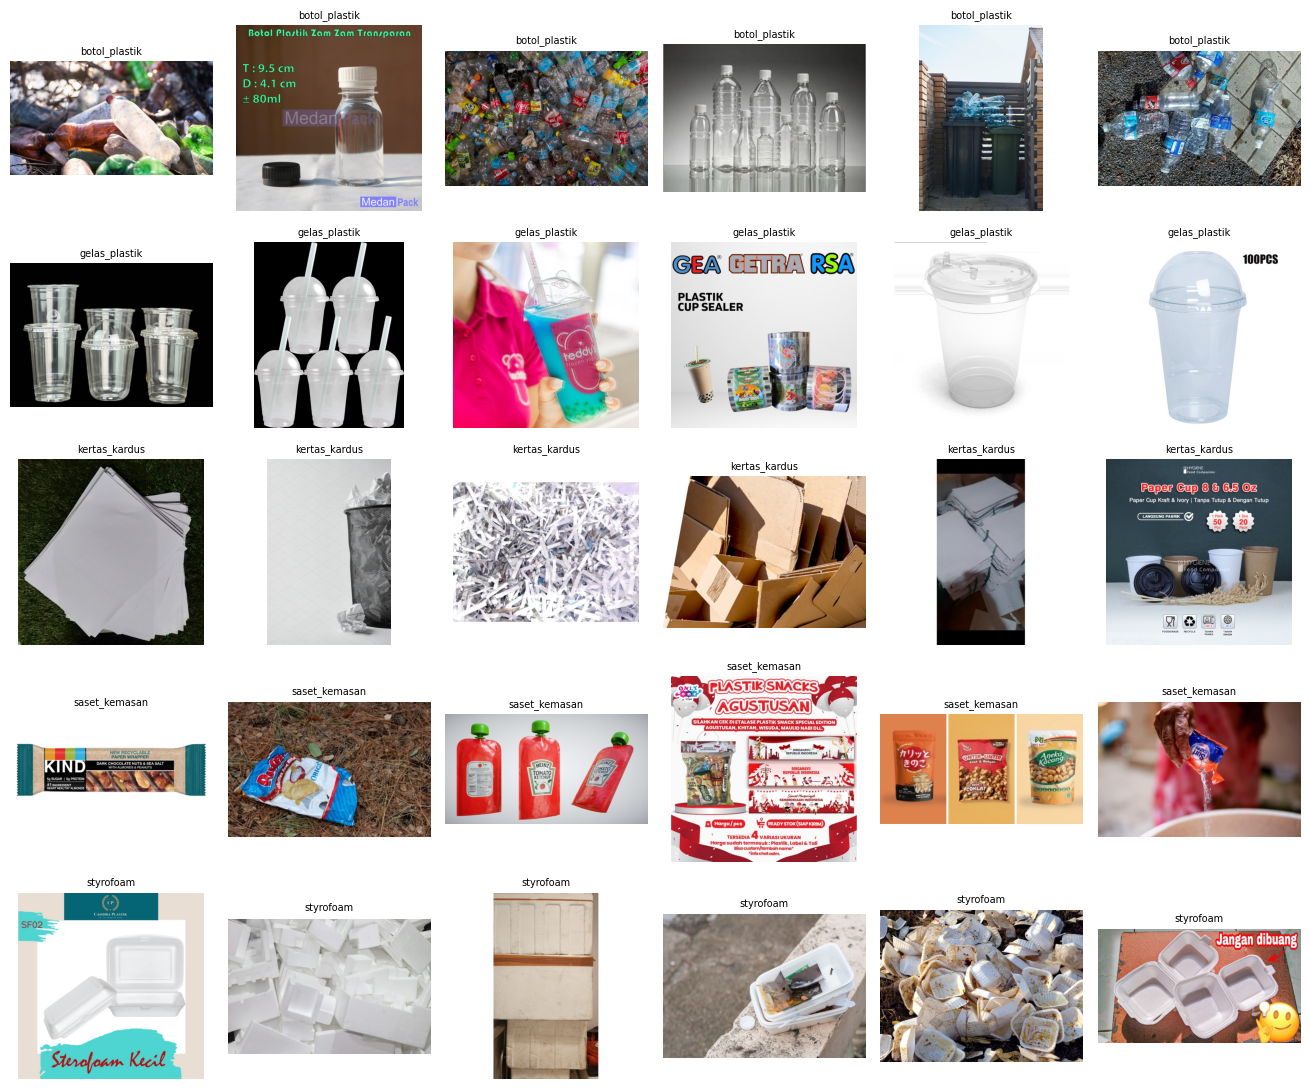

Ukuran gambar asli (piksel):


,w,h,kb
min,150.0,150.0,3.0
50%,800.0,753.0,101.0
max,1024.0,1024.0,501.0


Mode warna : {'RGB': 2753}

train_sources.csv tidak ditemukan


In [ ]:
def show_grid(paths, titles=None, ncols=6, size=2.2):
    n = len(paths)
    nrows = math.ceil(n / ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    axs = np.array(axs).reshape(-1)
    for ax in axs:
        ax.axis('off')
    for i, p in enumerate(paths):
        with Image.open(p) as im:
            axs[i].imshow(im.convert('RGB'))
        if titles is not None:
            axs[i].set_title(titles[i], fontsize=7)
    plt.tight_layout()
    plt.show()

rng = random.Random(cfg.seed)
pick = []
for ci in range(NUM_CLASSES):
    pool = [p for p, y in RAW_ITEMS if y == ci]
    pick += rng.sample(pool, min(6, len(pool)))
show_grid(pick, [CLASSES[[y for p, y in RAW_ITEMS if p == q][0]] for q in pick])

print('Ukuran gambar asli (piksel):')
display(clean[['w', 'h', 'kb']].describe().round(0).loc[['min', '50%', 'max']])
print('Mode warna :', clean['mode'].value_counts().to_dict())

# train_sources.csv (opsional)
SRC, src_df = {}, None
for cand in [cfg.sources_csv, DATA_ORIG / 'train_sources.csv', DATA_ORIG.parent / 'train_sources.csv',
             REPO / 'train_sources.csv','/content/train_sources.csv',
             '/content/drive/MyDrive/train_sources.csv']:
    if cand and Path(cand).exists():
        src_df = pd.read_csv(cand)
        print(f'\ntrain_sources.csv ditemukan: {cand}')
        break

if src_df is not None and {'file', 'label', 'page_url', 'title', 'image_url'} <= set(src_df.columns):
    SRC = {f'{Path(f).parent.name}/{Path(f).name}': dict(title=str(t), page_url=str(u), image_url=str(i))
           for f, t, u, i in zip(src_df.file, src_df.title, src_df.page_url, src_df.image_url)}
    dom = src_df.page_url.astype(str).str.extract(r'https?://([^/]+)')[0].str.replace(r'^www\.', '', regex=True)
    share = (src_df.groupby('page_url')['file'].transform('size') > 1).mean()
    print(f'{len(src_df)} baris | {src_df.page_url.nunique()} halaman sumber unik | {share:.0%} gambar berbagi halaman sumber dengan gambar lain')
    print('Domain teratas:', dom.value_counts().head(6).to_dict())
    print('Catatan: validasi tersembunyi diambil acak dari pengumpulan yang sama, jadi gambar dari halaman yang sama bisa ada di train dan validasi. '
          'Split acak lokal di bawah meniru kondisi ini.')
elif src_df is not None:
    print('Kolom train_sources.csv tidak sesuai harapan:', list(src_df.columns))
else:
    print('\ntrain_sources.csv tidak ditemukan')


def src_of(orig_path):
    return SRC.get(f'{Path(orig_path).parent.name}/{Path(orig_path).name}', {})

## 3. Split Validasi Lokal, `my_val/`, dan Cache Gambar


In [ ]:
y_all = np.array([l for _, l in RAW_ITEMS])
tr_idx, va_idx = train_test_split(np.arange(len(RAW_ITEMS)),
                                  test_size=cfg.val_frac, stratify=y_all,
                                  random_state=cfg.seed)
tr_idx, va_idx = np.sort(tr_idx), np.sort(va_idx)

EXTRA_RAW = []
for d in cfg.extra_dirs:
    EXTRA_RAW += list_items(d)


def cache_one(args):
    src, y, cache_dir, max_side = args
    tag = hashlib.md5(src.encode()).hexdigest()[:8]
    dst = Path(cache_dir) / CLASSES[y] / f'{Path(src).stem}_{tag}.jpg'
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(src) as im:
            # tanpa exif_transpose
            im = im.convert('RGB')
            if max(im.size) > max_side:
                s = max_side / max(im.size)
                im = im.resize((max(1, round(im.width * s)),
                                max(1, round(im.height * s))),
                               Image.Resampling.LANCZOS)
            im.save(dst, quality=95)
    return (str(dst), y)


def build_cache(items, cache_dir, max_side):
    jobs = [(p, y, cache_dir, max_side) for p, y in items]
    with ThreadPoolExecutor(max_workers=8) as ex:
        return list(tqdm(ex.map(cache_one, jobs), total=len(jobs),
                         desc='cache gambar'))

ALL_RAW = RAW_ITEMS + EXTRA_RAW
ALL_ITEMS = build_cache(ALL_RAW, cfg.cache_dir, cfg.cache_max_side) if cfg.cache_max_side > 0 else list(ALL_RAW)
# Path cache = path asli
ORIG_OF = {c: o for (c, _), (o, _) in zip(ALL_ITEMS, ALL_RAW)}
MAIN_ITEMS, EXTRA_ITEMS = ALL_ITEMS[:len(RAW_ITEMS)], ALL_ITEMS[len(RAW_ITEMS):]

# Terisi setelah audit label
EXCLUDE_NAMES = set()

def apply_exclude(items):
    return [it for it in items if Path(ORIG_OF[it[0]]).name not in EXCLUDE_NAMES]


SPLIT = dict(train=[MAIN_ITEMS[i] for i in tr_idx] + EXTRA_ITEMS,
             val=[MAIN_ITEMS[i] for i in va_idx])


def write_my_val(raw_items, idx, dst='my_val'):
    dst = Path(dst)
    if dst.exists():
        shutil.rmtree(dst)
    for i in idx:
        p, y = raw_items[i]
        out = dst / CLASSES[y]
        out.mkdir(parents=True, exist_ok=True)
        shutil.copy2(p, out / Path(p).name)


write_my_val(RAW_ITEMS, va_idx)
Path(cfg.runs_dir).mkdir(exist_ok=True)
Path(cfg.runs_dir, 'split.json').write_text(json.dumps(dict(
    seed=cfg.seed, val_frac=cfg.val_frac,
    val_files=[Path(RAW_ITEMS[i][0]).name for i in va_idx]), indent=1))

cnt = lambda its: np.bincount([y for _, y in its], minlength=NUM_CLASSES).tolist()
print(f'train: {len(SPLIT["train"])} (termasuk data tambahan: {len(EXTRA_ITEMS)}) | val: {len(SPLIT["val"])}')
print('per kelas  train:', cnt(SPLIT['train']), '| val:', cnt(SPLIT['val']))
print('my_val/ dibuat:', {c: len(list(Path('my_val', c).glob('*'))) for c in CLASSES})

cache gambar:   0%|          | 0/2753 [00:00<?, ?it/s]

train: 2340 (termasuk data tambahan: 0) | val: 413
per kelas  train: [445, 443, 310, 572, 570] | val: [78, 78, 55, 101, 101]
my_val/ dibuat: {'botol_plastik': 78, 'gelas_plastik': 78, 'kertas_kardus': 55, 'saset_kemasan': 101, 'styrofoam': 101}
